Step 1 – Import & Load Data


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import skfuzzy as fuzz
from skfuzzy import control as ctrl


In [2]:
file_path = r"..\data\processed\healthcare_processed.csv"
fuzzy_data = pd.read_csv(file_path)
fuzzy_data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,stroke_risk
0,9046,0,0.816895,0,1,1,3,1,0.801265,0.301260,1,1,1
1,51676,1,0.743652,0,0,1,4,0,0.679023,0.203895,0,1,1
2,31112,0,0.975586,0,1,1,3,0,0.234512,0.254296,0,1,2
3,60182,1,0.597168,0,0,1,3,1,0.536008,0.276060,2,1,2
4,1665,1,0.963379,1,0,1,4,0,0.549349,0.156930,0,1,2


In [3]:
fuzzy_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   int64  
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   int64  
 6   work_type          5110 non-null   int64  
 7   Residence_type     5110 non-null   int64  
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                5110 non-null   float64
 10  smoking_status     5110 non-null   int64  
 11  stroke             5110 non-null   int64  
 12  stroke_risk        5110 non-null   int64  
dtypes: float64(3), int64(10)
memory usage: 519.1 KB


In [4]:
fuzzy_data.describe().T

,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.829354,21161.721625,67.0,17741.250000,36932.000000,54682.000000,72940.0
gender,5110.0,0.586301,0.492941,0.0,0.000000,1.000000,1.000000,2.0
age,5110.0,0.526692,0.276033,0.0,0.304199,0.548340,0.743652,1.0
hypertension,5110.0,0.097456,0.296607,0.0,0.000000,0.000000,0.000000,1.0
heart_disease,5110.0,0.054012,0.226063,0.0,0.000000,0.000000,0.000000,1.0
ever_married,5110.0,0.656164,0.475034,0.0,0.000000,1.000000,1.000000,1.0
work_type,5110.0,2.495499,1.278532,0.0,1.000000,3.000000,3.000000,4.0
Residence_type,5110.0,0.508023,0.499985,0.0,0.000000,1.000000,1.000000,1.0
avg_glucose_level,5110.0,0.235563,0.209046,0.0,0.102137,0.169721,0.272228,1.0
bmi,5110.0,0.212624,0.088197,0.0,0.154639,0.203895,0.257732,1.0


In [5]:
fuzzy_data.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke', 'stroke_risk'],
      dtype='object')

In [6]:
# Select features for Fuzzy system
X_fuzzy = fuzzy_data[['age', 'bmi','gender','ever_married','work_type',
                      'smoking_status', 'avg_glucose_level', 'hypertension',
                      'heart_disease', 'Residence_type']]
y_fuzzy = fuzzy_data['stroke_risk']  # 0=Low, 1=Medium, 2=High

X_fuzzy.head()



,age,bmi,gender,ever_married,work_type,smoking_status,avg_glucose_level,hypertension,heart_disease,Residence_type
0,0.816895,0.301260,0,1,3,1,0.801265,0,1,1
1,0.743652,0.203895,1,1,4,0,0.679023,0,0,0
2,0.975586,0.254296,0,1,3,0,0.234512,0,1,0
3,0.597168,0.276060,1,1,3,2,0.536008,0,0,1
4,0.963379,0.156930,1,1,4,0,0.549349,1,0,0


Step 2 – Define Fuzzy Variables

In [7]:
# Step 2: Define Fuzzy Variables

# Input variables
age = ctrl.Antecedent(np.arange(0, 101, 1), 'age')  # 0-100 years
bmi = ctrl.Antecedent(np.arange(10, 60, 1), 'bmi')  # Body Mass Index
avg_glucose_level = ctrl.Antecedent(np.arange(50, 300, 1), 'avg_glucose_level')  # blood sugar

hypertension = ctrl.Antecedent(np.arange(0, 2, 1), 'hypertension')  # 0 or 1
heart_disease = ctrl.Antecedent(np.arange(0, 2, 1), 'heart_disease')  # 0 or 1

smoking_status = ctrl.Antecedent(np.arange(0, 3, 1), 'smoking_status')  # 0=never, 1=formerly, 2=smokes

# Output variable
stroke_risk = ctrl.Consequent(np.arange(0, 3, 1), 'stroke_risk')  # 0=Low, 1=Medium, 2=High


Step 3 – Define Membership Functions

In [8]:
# Step 3: Define Membership Functions

### -------- AGE -------- ###
age['young'] = fuzz.trapmf(age.universe, [0, 0, 25, 35])
age['middle'] = fuzz.trimf(age.universe, [30, 45, 60])
age['old'] = fuzz.trapmf(age.universe, [55, 65, 100, 100])


### -------- BMI -------- ###
bmi['low'] = fuzz.trapmf(bmi.universe, [10, 10, 18, 22])
bmi['normal'] = fuzz.trimf(bmi.universe, [20, 25, 30])
bmi['high'] = fuzz.trapmf(bmi.universe, [28, 32, 60, 60])


### -------- Glucose Level -------- ###
avg_glucose_level['normal'] = fuzz.trapmf(avg_glucose_level.universe, [50, 50, 90, 110])
avg_glucose_level['elevated'] = fuzz.trimf(avg_glucose_level.universe, [100, 130, 160])
avg_glucose_level['high'] = fuzz.trapmf(avg_glucose_level.universe, [150, 180, 300, 300])


### -------- Hypertension (Binary 0/1) -------- ###
hypertension['no'] = fuzz.trimf(hypertension.universe, [0, 0, 1])
hypertension['yes'] = fuzz.trimf(hypertension.universe, [0, 1, 1])


### -------- Heart Disease (Binary 0/1) -------- ###
heart_disease['no'] = fuzz.trimf(heart_disease.universe, [0, 0, 1])
heart_disease['yes'] = fuzz.trimf(heart_disease.universe, [0, 1, 1])


### -------- Smoking Status -------- ###
# 0=never, 1=formerly, 2=smokes
smoking_status['never'] = fuzz.trimf(smoking_status.universe, [0, 0, 1])
smoking_status['former'] = fuzz.trimf(smoking_status.universe, [0, 1, 2])
smoking_status['smokes'] = fuzz.trimf(smoking_status.universe, [1, 2, 2])


### -------- OUTPUT: Stroke Risk -------- ###
stroke_risk['low'] = fuzz.trimf(stroke_risk.universe, [0, 0, 1])
stroke_risk['medium'] = fuzz.trimf(stroke_risk.universe, [0, 1, 2])
stroke_risk['high'] = fuzz.trimf(stroke_risk.universe, [1, 2, 2])


Step 4 — Build Expert Fuzzy Rules

In [9]:
# Step 4: Define Fuzzy Rules
rules = []

### --- AGE + HEALTH CONDITIONS --- ###
rule1 = ctrl.Rule(age['old'] & hypertension['yes'], stroke_risk['high'])
rule2 = ctrl.Rule(age['old'] & heart_disease['yes'], stroke_risk['high'])
rule3 = ctrl.Rule(age['middle'] & hypertension['yes'], stroke_risk['medium'])
rule4 = ctrl.Rule(age['young'] & hypertension['yes'], stroke_risk['medium'])

### --- GLUCOSE + BMI --- ###
rule5 = ctrl.Rule(avg_glucose_level['high'] & bmi['high'], stroke_risk['high'])
rule6 = ctrl.Rule(avg_glucose_level['elevated'] & bmi['high'], stroke_risk['medium'])
rule7 = ctrl.Rule(avg_glucose_level['high'] & bmi['normal'], stroke_risk['medium'])
rule8 = ctrl.Rule(avg_glucose_level['normal'] & bmi['low'], stroke_risk['low'])

### --- SMOKING --- ###
rule9 = ctrl.Rule(smoking_status['smokes'] & age['old'], stroke_risk['high'])
rule10 = ctrl.Rule(smoking_status['smokes'] & age['middle'], stroke_risk['medium'])
rule11 = ctrl.Rule(smoking_status['former'] & age['old'], stroke_risk['medium'])
rule12 = ctrl.Rule(smoking_status['never'] & age['young'], stroke_risk['low'])

### --- HEART + HYPERTENSION INTERACTION --- ###
rule13 = ctrl.Rule(heart_disease['yes'] & hypertension['yes'], stroke_risk['high'])
rule14 = ctrl.Rule(heart_disease['no'] & hypertension['yes'], stroke_risk['medium'])
rule15 = ctrl.Rule(heart_disease['yes'] & hypertension['no'], stroke_risk['medium'])

### --- MIXED RISK BALANCING --- ###
rule16 = ctrl.Rule(age['old'] & bmi['high'], stroke_risk['high'])
rule17 = ctrl.Rule(age['middle'] & bmi['high'], stroke_risk['medium'])
rule18 = ctrl.Rule(age['young'] & bmi['normal'], stroke_risk['low'])

### --- ADD ALL RULES --- ###
rules = [rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8,
         rule9, rule10, rule11, rule12, rule13, rule14, rule15,
         rule16, rule17, rule18]


Step 5 — Build Fuzzy Control System + Predict + Evaluate

In [10]:
# Step 5: Build Fuzzy System

# Create control system
stroke_ctrl = ctrl.ControlSystem(rules)

# Simulation engine
stroke_sim = ctrl.ControlSystemSimulation(stroke_ctrl)


In [ ]:
#5.2 – Function to run the fuzzy model for one row

def fuzzy_predict_single(row):
    # Set inputs
    stroke_sim.input['age'] = row['age']
    stroke_sim.input['bmi'] = row['bmi']
    stroke_sim.input['avg_glucose_level'] = row['avg_glucose_level']
    stroke_sim.input['hypertension'] = row['hypertension']
    stroke_sim.input['heart_disease'] = row['heart_disease']
    stroke_sim.input['smoking_status'] = row['smoking_status']
    
    # Compute result
    try:
        stroke_sim.compute()
        output = stroke_sim.output['stroke_risk']
    except:
        output = 0  # fallback if something breaks
        
    # Convert continuous value → 0/1/2
    if output < 0.5:
        return 0
    elif output < 1.5:
        return 1
    else:
        return 2


In [ ]:
#5.3 – Apply model to entire dataset

predictions = []
for i in range(len(X_fuzzy)):
    pred = fuzzy_predict_single(X_fuzzy.iloc[i])
    predictions.append(pred)


In [14]:
#5.4 – Evaluate

from sklearn.metrics import accuracy_score, confusion_matrix

acc = accuracy_score(y_fuzzy, predictions)
cm = confusion_matrix(y_fuzzy, predictions)

print("Fuzzy Baseline Accuracy:", round(acc, 4))
print("Confusion Matrix:")
print(cm)


Fuzzy Baseline Accuracy: 0.6029
Confusion Matrix:
[[2685   90    0]
 [1287  396    0]
 [ 428  224    0]]


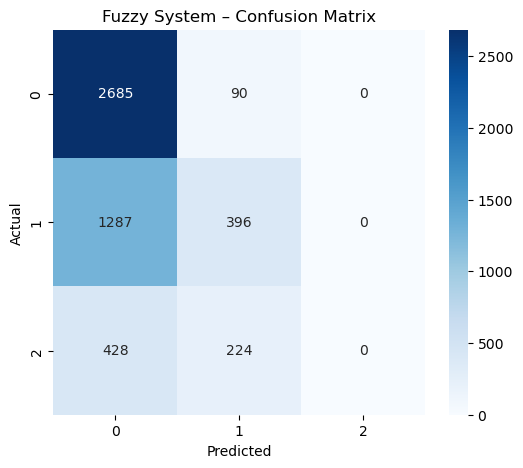

In [ ]:
import seaborn as sns


plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
plt.title("Fuzzy System – Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


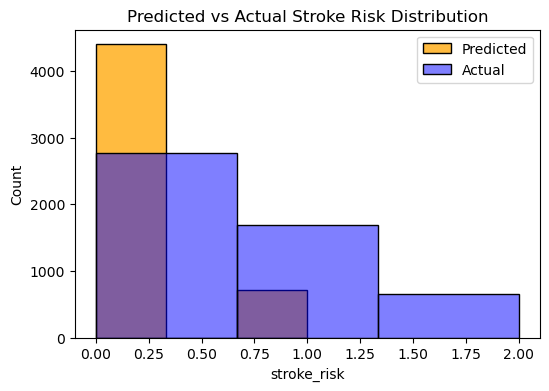

In [17]:
plt.figure(figsize=(6,4))
sns.histplot(predictions, kde=False, color='orange', label='Predicted', bins=3)
sns.histplot(y_fuzzy, kde=False, color='blue', label='Actual', bins=3, alpha=0.5)
plt.legend()
plt.title("Predicted vs Actual Stroke Risk Distribution")
plt.show()


In [18]:
sample = X_fuzzy.sample(5)
for idx, row in sample.iterrows():
    print("\n--- Sample", idx, "---")
    print("Age:", row['age'], "BMI:", row['bmi'],
          "Glucose:", row['avg_glucose_level'],
          "HT:", row['hypertension'], "HD:", row['heart_disease'],
          "Smoke:", row['smoking_status'])
    print("Predicted:", predictions[idx], " | True:", y_fuzzy.iloc[idx])



--- Sample 843 ---
Age: 0.23095703125 BMI: 0.1649484536082474 Glucose: 0.1335980057243098 HT: 0.0 HD: 0.0 Smoke: 0.0
Predicted: 0  | True: 0

--- Sample 1468 ---
Age: 0.5849609375 BMI: 0.2038946162657502 Glucose: 0.7467454528667713 HT: 0.0 HD: 0.0 Smoke: 2.0
Predicted: 0  | True: 1

--- Sample 1522 ---
Age: 0.951171875 BMI: 0.2760595647193585 Glucose: 0.1630043393961777 HT: 0.0 HD: 0.0 Smoke: 1.0
Predicted: 0  | True: 2

--- Sample 2253 ---
Age: 0.52392578125 BMI: 0.2508591065292097 Glucose: 0.2134151971193795 HT: 0.0 HD: 0.0 Smoke: 0.0
Predicted: 0  | True: 0

--- Sample 830 ---
Age: 0.0234375 BMI: 0.1111111111111111 Glucose: 0.2491921336903333 HT: 0.0 HD: 0.0 Smoke: 3.0
Predicted: 0  | True: 0


In [1]:
import pickle

system_spec = {
    "universes": {
        "age": [0, 100],
        "bmi": [10, 60],
        "avg_glucose_level": [50, 300],
        "hypertension": [0, 1],
        "heart_disease": [0, 1],
        "smoking_status": [0, 2],
        "gender": [0, 2],
        "ever_married": [0, 1],
        "work_type": [0, 4],
        "Residence_type": [0, 1]
    },

    "mfs": {
        "age": {
            "young": {"type": "trap", "params": [0, 0, 25, 35]},
            "middle": {"type": "trimf", "params": [30, 45, 60]},
            "old": {"type": "trap", "params": [55, 65, 100, 100]}
        },

        "bmi": {
            "low": {"type": "trap", "params": [10, 10, 18, 22]},
            "normal": {"type": "trimf", "params": [20, 25, 30]},
            "high": {"type": "trap", "params": [28, 32, 60, 60]}
        },

        "avg_glucose_level": {
            "normal": {"type": "trap", "params": [50, 50, 90, 110]},
            "elevated": {"type": "trimf", "params": [100, 130, 160]},
            "high": {"type": "trap", "params": [150, 180, 300, 300]}
        },

        "hypertension": {
            "no": {"type": "trimf", "params": [0, 0, 1]},
            "yes": {"type": "trimf", "params": [0, 1, 1]}
        },

        "heart_disease": {
            "no": {"type": "trimf", "params": [0, 0, 1]},
            "yes": {"type": "trimf", "params": [0, 1, 1]}
        },

        "smoking_status": {
            "never": {"type": "trimf", "params": [0, 0, 1]},
            "former": {"type": "trimf", "params": [0, 1, 2]},
            "smokes": {"type": "trimf", "params": [1, 2, 2]}
        },

        # ——— Singletons for categoricals (you didn't define MFs for them) ———
        "gender": {
            "male": {"type": "singleton", "params": [0]},
            "female": {"type": "singleton", "params": [1]},
            "other": {"type": "singleton", "params": [2]}
        },

        "ever_married": {
            "no": {"type": "singleton", "params": [0]},
            "yes": {"type": "singleton", "params": [1]}
        },

        "work_type": {
            "children": {"type": "singleton", "params": [0]},
            "govt_job": {"type": "singleton", "params": [1]},
            "never_worked": {"type": "singleton", "params": [2]},
            "private": {"type": "singleton", "params": [3]},
            "self_employed": {"type": "singleton", "params": [4]}
        },

        "Residence_type": {
            "rural": {"type": "singleton", "params": [0]},
            "urban": {"type": "singleton", "params": [1]}
        }
    },

    # RULES — completely identical to Notebook 3 definitions
    "rules": [
        ({"age": "old", "hypertension": "yes"}, {"stroke_risk": "high"}),
        ({"age": "old", "heart_disease": "yes"}, {"stroke_risk": "high"}),
        ({"age": "middle", "hypertension": "yes"}, {"stroke_risk": "medium"}),
        ({"age": "young", "hypertension": "yes"}, {"stroke_risk": "medium"}),

        ({"avg_glucose_level": "high", "bmi": "high"}, {"stroke_risk": "high"}),
        ({"avg_glucose_level": "elevated", "bmi": "high"}, {"stroke_risk": "medium"}),
        ({"avg_glucose_level": "high", "bmi": "normal"}, {"stroke_risk": "medium"}),
        ({"avg_glucose_level": "normal", "bmi": "low"}, {"stroke_risk": "low"}),

        ({"smoking_status": "smokes", "age": "old"}, {"stroke_risk": "high"}),
        ({"smoking_status": "smokes", "age": "middle"}, {"stroke_risk": "medium"}),
        ({"smoking_status": "former", "age": "old"}, {"stroke_risk": "medium"}),
        ({"smoking_status": "never", "age": "young"}, {"stroke_risk": "low"}),

        ({"heart_disease": "yes", "hypertension": "yes"}, {"stroke_risk": "high"}),
        ({"heart_disease": "no", "hypertension": "yes"}, {"stroke_risk": "medium"}),
        ({"heart_disease": "yes", "hypertension": "no"}, {"stroke_risk": "medium"}),

        ({"age": "old", "bmi": "high"}, {"stroke_risk": "high"}),
        ({"age": "middle", "bmi": "high"}, {"stroke_risk": "medium"}),
        ({"age": "young", "bmi": "normal"}, {"stroke_risk": "low"})
    ]
}

# SAVE
with open("fuzzy_system_spec.pkl", "wb") as f:
    pickle.dump(system_spec, f)

print("Saved fuzzy_system_spec.pkl — complete Fuzzy System Spec exported.")


Saved fuzzy_system_spec.pkl — complete Fuzzy System Spec exported.
